# Search and Download AVIRIS-3 Granules for a Study Area

## Overview

During the **[AVUELO](https://www.earthdata.nasa.gov/data/projects/avuelo)** campaign in February 2025, AVIRIS-3 flew several flight lines over Panama and Costa Rica. Many flight lines overlap, and each flight line is cut into many scenes. A study area is often covered by several scenes from different days, flight altitudes, and pixel sizes. Each scene is about 1 GB. We should identify the right scenes before downloading.

In this tutorial, we use the outline of a plot in Panama as the study area polygon. We will:

1. search for AVIRIS-3 granules over the polygon with [NASA Earthdata Search](https://search.earthdata.nasa.gov/) and with `earthaccess`
2. find the pixel size of each scene and how much of the study area it actually covers, without downloading the files
3. download the selected granules with Earthdata Search and with Python

## Requirements

- A NASA [Earthdata Login](https://urs.earthdata.nasa.gov/) account
- See the [prerequisites](../../docs/prerequisites.md) page for setup instructions.

## AVUELO Datasets

The AVUELO datasets published so far are listed on the [AVUELO data access page](https://www.earthdata.nasa.gov/data/projects/avuelo/data-access-tools). 

| Dataset | Short name | DOI |
|---|---|---|
| AVUELO AVIRIS-3 Orthocorrected Surface Reflectance (provisional calibration) | `AVUELO_AV3_L2A_Reflectance_2479` | [10.3334/ORNLDAAC/2479](https://doi.org/10.3334/ORNLDAAC/2479) |

## Import Libraries

In [1]:
import pyproj
from concurrent.futures import ThreadPoolExecutor
import earthaccess
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
from shapely.geometry.polygon import orient
import warnings
warnings.filterwarnings('ignore')

# ESRI basemap for interactive maps
xyz = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
attr = "ESRI"

## Study Area Polygon

The file `data/avuelo_forest_plots.geojson` contains approximate outlines of the nine forest plots in the [AVUELO tree crown dataset](https://doi.org/10.3334/ORNLDAAC/2517). Each outline is made by drawing the smallest rectangle around the mapped tree crowns of the plot. Any polygon file that `geopandas` can read (GeoJSON, shapefile, KML, GeoPackage) should work the same way.

In [2]:
plots = gpd.read_file('data/avuelo_forest_plots.geojson')
plots

,plot_code,name,site,area_ha,geometry
0,ava,BCI AVA plot,Barro Colorado Island,4.8,"POLYGON ((-79.84791 9.1562, -79.84944 9.15611,..."
1,drayton,BCI Drayton plot,Barro Colorado Island,6.9,"POLYGON ((-79.84446 9.14854, -79.84645 9.14844..."
2,gigante,Gigante fertilization plot,Gigante Peninsula,40.7,"POLYGON ((-79.85597 9.09888, -79.85622 9.10628..."
3,p10,BCI 10-ha plot,Barro Colorado Island,12.4,"POLYGON ((-79.85516 9.15568, -79.85512 9.15678..."
4,p25,BCI 25-ha plot,Barro Colorado Island,27.1,"POLYGON ((-79.84818 9.15631, -79.84831 9.16106..."
5,p50,BCI 50-ha plot,Barro Colorado Island,53.5,"POLYGON ((-79.84592 9.15551, -79.8461 9.15078,..."
6,pearson,BCI Pearson plot,Barro Colorado Island,7.2,"POLYGON ((-79.85183 9.16218, -79.85385 9.1621,..."
7,sherman,San Lorenzo (Sherman) plot,San Lorenzo,11.7,"POLYGON ((-79.97292 9.28033, -79.97526 9.28033..."
8,zetek,BCI Zetek plot,Barro Colorado Island,6.7,"POLYGON ((-79.85914 9.15304, -79.85922 9.15582..."


We plot the above geopandas dataframe as a map.

In [3]:
plots.explore(column='plot_code', tiles=xyz, attr=attr, tooltip=['name', 'area_ha'],
              style_kwds={'fillOpacity': 0.2})

We select the BCI 50-ha plot as our study area. Also, we plot the study area below.

In [4]:
study_area = plots[plots.plot_code == 'p50']
study_area.explore(tiles=xyz, attr=attr,
                   style_kwds={'fill': False, 'color': 'yellow'})

## Part 1: Search and Download with NASA Earthdata Search

*Step 1.* Open the AVUELO AVIRIS-3 reflectance granules in Earthdata Search: https://search.earthdata.nasa.gov/search/granules?p=C3906206748-ORNL_CLOUD

*Step 2.* **Spatial filter**: click the spatial search icon in the search bar and choose **File (KML, KMZ, ESRI, …)**. Upload `data/avuelo_forest_plots.geojson`. Click the BCI 50-ha plot polygon on the map to use it as the filter.

![Earthdata Spatial Search for AVUELO](images/avuelo_spatial.png)

*Step 3.* **Granule filter**: click **Filter Granules** and type `*RFL_ORT.nc` in the **Granule ID(s)** box to keep only the reflectance files. Use `*UNC_ORT.nc` for the uncertainty files.

![Earthdata Spatial Granule Search for AVUELO](images/avuelo_spatial2.png)

*Step 4.* Click a granule in the list to see its file name and size, and its footprint on the map.

*Step 5.* Click **Download All**, then **Edit Options**. Choose **Direct Download** and click **Download Data**.

*Step 6.* On the download status page, there are several ways to download the files, including using [Earthdata Download](https://www.earthdata.nasa.gov/news/earthdata-download-simplifies-large-data-requests), a free desktop application.

## Part 2: Search with `earthaccess`
## Authentication
`earthaccess.login()` authenticates with your Earthdata Login credentials. If you have a `.netrc` file or `EARTHDATA_USERNAME` and `EARTHDATA_PASSWORD` environment variables, login completes without a prompt. Searching does not require login, but streaming and downloading data do.

In [5]:
auth = earthaccess.login()

### Search granules with the polygon

NASA CMR (the meatadata catalog behind Earthdata Search) needs polygon vertices in counter-clockwise order, and it limits the number of vertices. We orient the polygon counter-clockwise with `shapely` and simplify it if it has many vertices.

Next, we search for the [AVUELO AVIRIS-3 reflectance](https://doi.org/10.3334/ORNLDAAC/2479)(Shortname: `AVUELO_AV3_L2A_Reflectance_2479`)  granules within the spatial limit of the `coords` above. Each scene in the AVUELO reflectance dataset has two files, and each file is a separate granule in CMR:

| Product | Contents |
|---|---|
| `RFL_ORT` | Orthorectified surface reflectance, aerosol optical thickness, and water vapor |
| `UNC_ORT` | Reflectance uncertainty (one standard deviation) |


In [6]:
# polygon vertices in counter-clockwise order
poly = orient(study_area.geometry.iloc[0], sign=1.0)
# simplify with a tolerance of 0.0001 degrees (~10 m) if many vertices
poly = poly.simplify(0.0001)
coords = list(poly.exterior.coords)
coords

[(-79.845917, 9.155506),
 (-79.855225, 9.155857),
 (-79.855406, 9.151131),
 (-79.846098, 9.150779),
 (-79.845917, 9.155506)]

In [7]:
short_name = 'AVUELO_AV3_L2A_Reflectance_2479'
results = earthaccess.search_data(short_name=short_name, polygon=coords)
print(f"Granules found: {len(results)}")

Granules found: 38


`earthaccess.search_data()` takes other filters too. For example, `granule_name` filters by file name with wildcards (`*` matches any characters). Here we keep only the reflectance files (`RFL_ORT`).

In [8]:
rfl_results = earthaccess.search_data(short_name=short_name, polygon=coords,
                                      granule_name='*RFL_ORT*')
print(f"Reflectance granules found: {len(rfl_results)}")

Reflectance granules found: 19


### Granule metadata

We put the granule metadata in a `geopandas` dataframe. The flight line and scene number come from the file name.

In [9]:
def granule_details(g):
    """Returns AVIRIS-3 granule metadata as a dictionary."""
    name = g['umm']['GranuleUR'].split('.', 1)[1]
    parts = name.split('_')
    return {
        'scene_id': f"{parts[0]}_{parts[1]}",
        'flight_line': parts[0],
        'start_time': pd.to_datetime(g['umm']['TemporalExtent']['RangeDateTime']['BeginningDateTime']),
        'size_mb': round(g['size']),
        'url': g.data_links()[0],
    }
# create a geopandas dataframe from granule details
gdf = gpd.GeoDataFrame([granule_details(g) for g in rfl_results],
                       geometry=gpd.GeoSeries(rfl_results, crs='EPSG:4326'))
# sorting by start time
gdf = gdf.sort_values('start_time').reset_index(drop=True)
gdf[['scene_id', 'flight_line', 'start_time', 'size_mb']]

,scene_id,flight_line,start_time,size_mb,url,geometry
0,AV320250206t193402_006,AV320250206t193402,2025-02-06 19:37:49+00:00,993,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.8769 9.13979, -79.8251 9.1..."
1,AV320250206t193402_007,AV320250206t193402,2025-02-06 19:38:24+00:00,981,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.8512 9.11419, -79.7993 9.1..."
2,AV320250206t194805_009,AV320250206t194805,2025-02-06 19:53:38+00:00,1141,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.8741 9.09693, -79.8144 9.0..."
3,AV320250206t194805_010,AV320250206t194805,2025-02-06 19:54:14+00:00,1139,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.9044 9.12667, -79.844 9.12..."
4,AV320250206t202709_002,AV320250206t202709,2025-02-06 20:28:45+00:00,1132,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.895 9.13773, -79.8479 9.13..."
5,AV320250206t202709_003,AV320250206t202709,2025-02-06 20:29:27+00:00,1121,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.8539 9.13025, -79.8063 9.1..."
6,AV320250210t163840_010,AV320250210t163840,2025-02-10 16:44:49+00:00,1043,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.8787 9.10402, -79.8217 9.1..."
7,AV320250210t163840_011,AV320250210t163840,2025-02-10 16:45:25+00:00,1024,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.9056 9.13089, -79.8493 9.1..."
8,AV320250210t165202_006,AV320250210t165202,2025-02-10 16:55:49+00:00,1072,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.864 9.12522, -79.8096 9.12..."
9,AV320250210t190253_011,AV320250210t190253,2025-02-10 19:05:16+00:00,922,https://data.ornldaac.earthdata.nasa.gov/prote...,"MULTIPOLYGON (((-79.8586 9.15207, -79.846 9.15..."


We plot the above dataframe and look at how they overlaps our study area BCI 50-ha plot.

In [10]:
m = gdf.explore(column='scene_id', tiles=xyz, attr=attr,
                tooltip=['scene_id', 'start_time'],
                style_kwds={'fillOpacity': 0.1, 'weight': 1})
# ploting the study area in yellow
study_area.explore(m=m, style_kwds={'color': 'yellow', 'weight': 3})

As we see above, the study area is overlaps several flight lines on different days. The rectangles on the map are the bounding boxes stored in CMR, which are often larger than the actual images. Some of these scenes may cover only a corner of the study area, or none of it.

### Filter by pixel coverage

AVIRIS-3 flew at different altitudes, so the pixel size differs between flight lines. Most areas were collected at ~3 m and some sites at ~1 m. The pixel size is not in the CMR metadata, but we can read it from the file without downloading the whole file. `earthaccess.open()` opens a remote file, and `xarray` only reads the parts of the file.

In [11]:
# open the list of files
files = earthaccess.open(list(gdf.url))

# open the first file to read its coordinate reference system
da = xr.open_datatree(files[0], engine='h5netcdf')
crs = pyproj.CRS.from_wkt(da['transverse_mercator'].attrs['crs_wkt'])
print(f"CRS: {crs.name} (EPSG:{crs.to_epsg()})")

QUEUEING TASKS | :   0%|          | 0/19 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/19 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/19 [00:00<?, ?it/s]

CRS: WGS 84 / UTM zone 17N (EPSG:32617)


The data files are projected to UTM 17N projection (`EPSG: 32617`).

To compute the coverage, we create a grid of points spaced 10 m apart within the study area and check how many points have valid data in each scene. The function below reads a single band water vapor (`water_vapor`) layer of each file, which is much smaller than the 284-band `reflectance`.

In [12]:
def scene_info(f):
    """Returns pixel size (m) and % of study area with valid data."""
    da = xr.open_datatree(f, engine='h5netcdf')
    # pixel size as difference of two adjacent eastings
    pixel_size = float(da['easting'].diff('easting')[0])
    # water vapor is a 2D band
    wv = da['water_vapor']['water_vapor']
    # keep only the window around the study area
    wv = wv.sel(easting=slice(xmin - pixel_size, xmax + pixel_size),
                northing=slice(ymax + pixel_size, ymin - pixel_size))
    # find water vapor values within the study area
    vals = wv.sel(easting=gx, northing=gy, method='nearest').values
    inside = ((gx >= wv.easting.min()) & (gx <= wv.easting.max()) &
              (gy >= wv.northing.min()) & (gy <= wv.northing.max())).values
    # valid values inside study area, excluding fill values
    valid = inside & (vals != -9999) & ~np.isnan(vals)
    return pixel_size, round(100 * valid.mean(), 1)

# projecting study area to AV3 projection
sa_utm = study_area.to_crs(crs).geometry.iloc[0]
# bounds in UTM coordinates
xmin, ymin, xmax, ymax = sa_utm.bounds
# create meshgrid at 10m steps
xx, yy = np.meshgrid(np.arange(xmin, xmax, 10),
                     np.arange(ymin, ymax, 10))
# create a geopandas series from x, y coordinates
# from meshgrid
grid = gpd.GeoSeries(
    gpd.points_from_xy(xx.ravel(),
                       yy.ravel()), crs=crs
)
grid = grid[grid.within(sa_utm)]

# converting to xarray
gx = xr.DataArray(grid.x.values, dims='points')
gy = xr.DataArray(grid.y.values, dims='points')

# parallel processing scene_info function over multithreads
with ThreadPoolExecutor(max_workers=4) as pool:
    info = list(pool.map(scene_info, files))

# adding results as new columns to the dataframe
gdf['pixel_size_m'] = [round(i[0], 1) for i in info]
gdf['coverage_pct'] = [i[1] for i in info]
gdf[['scene_id', 'start_time', 'size_mb', 'pixel_size_m', 'coverage_pct']]

,scene_id,start_time,size_mb,pixel_size_m,coverage_pct
0,AV320250206t193402_006,2025-02-06 19:37:49+00:00,993,3.4,100.0
1,AV320250206t193402_007,2025-02-06 19:38:24+00:00,981,3.4,0.0
2,AV320250206t194805_009,2025-02-06 19:53:38+00:00,1141,3.4,0.0
3,AV320250206t194805_010,2025-02-06 19:54:14+00:00,1139,3.4,94.9
4,AV320250206t202709_002,2025-02-06 20:28:45+00:00,1132,3.4,26.7
5,AV320250206t202709_003,2025-02-06 20:29:27+00:00,1121,3.4,73.3
6,AV320250210t163840_010,2025-02-10 16:44:49+00:00,1043,3.4,60.9
7,AV320250210t163840_011,2025-02-10 16:45:25+00:00,1024,3.4,32.1
8,AV320250210t165202_006,2025-02-10 16:55:49+00:00,1072,3.4,100.0
9,AV320250210t190253_011,2025-02-10 19:05:16+00:00,922,1.1,52.3


The above table shows that: (1) scenes have pixel sizes of 1.1 m or 3.3-3.4 m, depending on the flight altitude, and (2) several scenes cover the whole plot (100% coverage) while some scenes do not cover the plot at all (0% coverage).

### Filter by cloud cover
Coverage is not the only criterion. Clouds and cloud shadows are common over Panama, and the provisional L2A product has no cloud mask. Looking at a true-color image of the study area is the quickest check. We read only three bands (red, green, blue) for the study area window for the scenes with >95% pixel coverage.

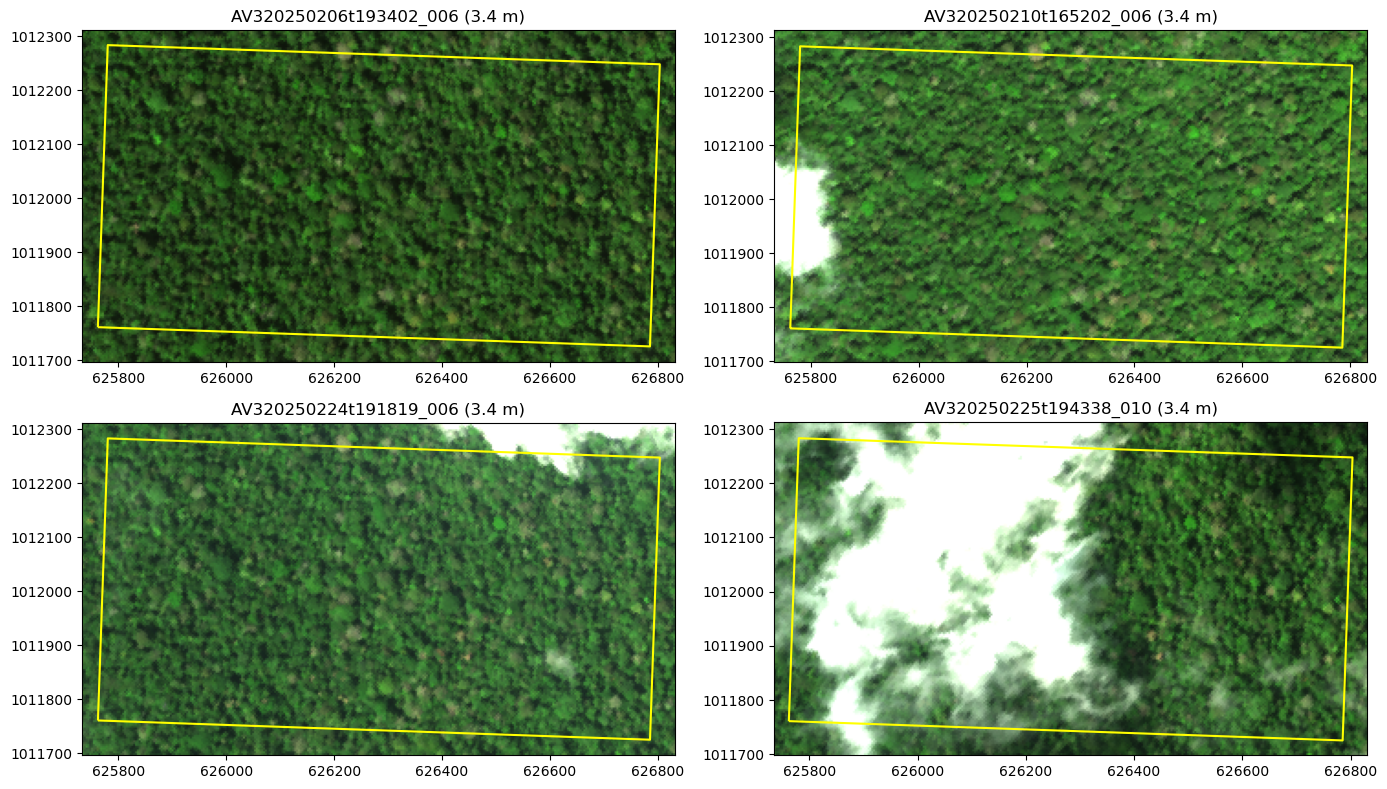

In [13]:
def true_color(f, bounds, pad=30):
    """Returns RGB bands as array for a bound and its extent."""
    x0, y0, x1, y1 = bounds
    da = xr.open_datatree(f, engine='h5netcdf')['reflectance']['reflectance']
    sub = da.sel(easting=slice(x0 - pad, x1 + pad),
                 northing=slice(y1 + pad, y0 - pad))
    sub = sub.sel(wavelength=[650, 560, 470],
                  method='nearest').load()
    sub = sub.where(sub != -9999)
    rgb = np.clip(sub.values.transpose(1, 2, 0) / 0.1, 0, 1)
    extent = [float(sub.easting.min()), float(sub.easting.max()),
              float(sub.northing.min()), float(sub.northing.max())]
    return rgb, extent

# all scenes that has more than 95% pixel coverage
candidates = gdf[gdf.coverage_pct>=95]['scene_id'].to_list()
# number of scenes
n = len(candidates)
# two scenes per row
ncols = 2
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows*4))
# loop over each scene and plot RGB
for ax, sid in zip(axes.flatten(), candidates):
    i = gdf.index[gdf.scene_id == sid][0]
    rgb, extent = true_color(files[i], sa_utm.bounds)
    ax.imshow(rgb, extent=extent)
    # study area bounds
    gpd.GeoSeries([sa_utm]).boundary.plot(ax=ax,
                                          color='yellow')
    ax.set_title(f"{sid} ({gdf.pixel_size_m[i]} m)")
    ax.ticklabel_format(style='plain')
plt.tight_layout()
plt.show()

Of the four scenes, only one scene **`AV320250206t193402_006`** covers all the pixels within the study area with no clouds.. 

## Download Files

Each scene has a reflectance (`RFL_ORT`) and an uncertainty (`UNC_ORT`) granule. We search both granules for the selected scene by name and download them with `earthaccess.download()`. Files that already exist locally are skipped.

The AVUELO data are stored in Amazon Web Services (AWS) region `us-west-2`. When you run these notebooks on a computer in the same region, such as a cloud-hosted JupyterHub, `earthaccess.open()` instead of `earthaccess.download()` reads directly from S3, which is much faster than from a local computer.

In [14]:
scene_id = 'AV320250206t193402_006'
scene_granules = earthaccess.search_data(short_name=short_name,
                                         granule_name=f'*{scene_id}*')
for g in scene_granules:
    print(g['umm']['GranuleUR'], f"{g['size']:.0f} MB")

AVUELO_AV3_L2A_Reflectance.AV320250206t193402_006_L2A_OE_5988d8f5_RFL_ORT.nc 993 MB
AVUELO_AV3_L2A_Reflectance.AV320250206t193402_006_L2A_OE_5988d8f5_UNC_ORT.nc 1070 MB


In [15]:
downloaded = earthaccess.download(scene_granules, local_path='downloads')
downloaded

QUEUEING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/2 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/2 [00:00<?, ?it/s]

[PosixPath('downloads/AV320250206t193402_006_L2A_OE_5988d8f5_RFL_ORT.nc'),
 PosixPath('downloads/AV320250206t193402_006_L2A_OE_5988d8f5_UNC_ORT.nc')]

### Download many granules
The same function downloads a list of granules in parallel. Four parallel downloads (`threads=4`) are usually faster. For example, the cell below would download all reflectance and uncertainty granules that cover at least half of the study area. Check the total size before you download.

In [16]:
selected = gdf[gdf.coverage_pct >= 50]
print(f"{len(selected)} scenes, {2 * selected.size_mb.sum() / 1024:.1f} GB (reflectance + uncertainty)")
# urls of both RFL_ORT and UNC_ORT files
urls = [u for u in selected.url] + [u.replace('_RFL_ORT.nc', '_UNC_ORT.nc') for u in selected.url]
# uncomment to download
# earthaccess.download(urls, local_path='data', threads=4)

10 scenes, 20.5 GB (reflectance + uncertainty)


### Save a list of links

You can also save the links to a text file to download them later with `wget` or `curl`.

In [17]:
with open('data/avuelo_p50_links.txt', 'w') as f:
    f.write('\n'.join(urls))